# U-Chrom Imaging Pipeline

Data moves through memory by default. Set `SAVE_MODE` to save selected or pyHiM-style artifacts under `OUT_DIR`.

## Section 1: Load Raw Data

In [23]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import importlib
import uchrom.im.compare as im_compare
im_compare = importlib.reload(im_compare)

from uchrom.im import (
    ImWorkspace,
    segment,
    localize,
    filter_localizations,
    register_localizations,
    build_traces,
    build_matrix,
)
from uchrom.im.compare import (
    finite_array_metrics,
    first_existing,
    foreground_scores,
    label_iou_matches,
    localization_count_summary,
    mask_summary,
    match_localizations_by_position,
    matrix_metrics,
    plot_localization_xy,
    read_ecsv,
    show_array_comparison,
    show_3d_call_alignment_qc,
    show_barcode_localization_qc,
    show_barcode_xy_shift_and_call_qc,
    show_mask_overlay,
    show_mask_segmentation_qc,
    show_matrix_comparison,
    show_local_registration_3d_qc,
    show_localization_match_diagnostics,
    show_registration_qc_comparison,
    trace_summary,
)

RAW_DIR = Path(r"F:/project/Caolab/U-C-p/UC/test_data/raw")
OUT_DIR = Path(r"F:/project/Caolab/U-C-p/UC/test_data")
PYHIM_DIR = Path(r"F:/project/Caolab/U-C-p/pyHiM/test/test_dataset")
PYHIM_ANALYSIS_DIR = PYHIM_DIR / "analysis_localizations"

SAVE_MODE = False      # False, "selected", or "all"
SAMPLE_ID = "scan_001"
ROI = "005"
REFERENCE_ROUND = "RT26"
Z_BINNING = 2
# Format: (y0, y1, x0, x1). Use None to show the full field of view.
REGISTRATION_QC_ZOOM = (300, 700, 300, 700)
# Block-window format: (row0, row1, col0, col1). Use None for full field of view.
LOCAL_REGISTRATION_3D_QC_ROUND = "RT27"
LOCAL_REGISTRATION_3D_QC_BLOCK_WINDOW = None
LOCAL_REGISTRATION_3D_QC_Z_CROP = None  # Format: (y0, y1, x0, x1) for Z-projection only.
# pyHiM register_localizations defaults: anisotropic tolerance in (z, y-row, x-col) shift axes.
LOCALIZATION_TOLERANCE_DRIFT = (3, 1, 1)
REMOVE_UNCORRECTED_LOCALIZATIONS = True
SEGMENTATION_QC_CROP = None  # Format: (y0, y1, x0, x1).
LOCALIZATION_QC_CROP = None  # Format: (y0, y1, x0, x1).


In [2]:
manifest = {
    "RT26": {
        "fiducial": {"path": RAW_DIR / "scan_001_RT26_005_ROI_converted_decon_ch00.tif"},
        "images": {"barcode": {"path": RAW_DIR / "scan_001_RT26_005_ROI_converted_decon_ch01.tif"}},
        "meta": {"sample_id": SAMPLE_ID, "roi": ROI},
    },
    "RT27": {
        "fiducial": {"path": RAW_DIR / "scan_001_RT27_005_ROI_converted_decon_ch00.tif"},
        "images": {"barcode": {"path": RAW_DIR / "scan_001_RT27_005_ROI_converted_decon_ch01.tif"}},
        "meta": {"sample_id": SAMPLE_ID, "roi": ROI},
    },
    "DAPI": {
        "fiducial": {"path": RAW_DIR / "scan_001_DAPI_005_ROI_converted_decon_ch01.tif"},
        "images": {"dapi": {"path": RAW_DIR / "scan_001_DAPI_005_ROI_converted_decon_ch00.tif"}},
        "meta": {"sample_id": SAMPLE_ID, "roi": ROI},
    },
}

workspace = ImWorkspace.from_manifest(manifest, meta={"sample_id": SAMPLE_ID, "roi": ROI})
list(workspace.raw_rounds)

['RT26', 'RT27', 'DAPI']

In [3]:
workspace.raw_rounds["RT26"]["fiducial"].data.shape

(70, 1024, 1024)

In [4]:
workspace

ImWorkspace(raw_rounds={'RT26': {'fiducial': Image3D(data=array([[[69, 67, 66, ..., 74, 73, 75],
        [68, 66, 66, ..., 70, 68, 68],
        [69, 67, 67, ..., 69, 67, 67],
        ...,
        [73, 77, 78, ..., 45, 46, 47],
        [69, 72, 74, ..., 46, 46, 47],
        [68, 71, 72, ..., 50, 49, 47]],

       [[66, 65, 62, ..., 83, 78, 76],
        [64, 64, 64, ..., 80, 75, 73],
        [61, 62, 65, ..., 77, 73, 73],
        ...,
        [73, 80, 80, ..., 48, 49, 47],
        [69, 74, 74, ..., 47, 47, 46],
        [68, 71, 70, ..., 47, 46, 44]],

       [[63, 64, 61, ..., 87, 79, 72],
        [62, 65, 66, ..., 82, 73, 67],
        [62, 66, 71, ..., 80, 71, 66],
        ...,
        [79, 81, 78, ..., 53, 53, 53],
        [75, 76, 75, ..., 50, 51, 52],
        [71, 72, 73, ..., 46, 47, 49]],

       ...,

       [[45, 45, 48, ..., 57, 57, 53],
        [46, 46, 48, ..., 58, 58, 55],
        [49, 48, 49, ..., 58, 59, 56],
        ...,
        [50, 46, 43, ..., 48, 52, 58],
        [46, 

## Section 1.5: pyHiM Comparison Setup

The comparison cells use pyHiM outputs as references. Metrics are chosen by data type: pixel-wise metrics for arrays, label-aware IoU for masks, coordinate nearest-neighbor matching for localizations, and summary/matrix comparisons for traces.


In [ ]:
PYHIM_PROJECT_DATA = PYHIM_DIR / "project" / "data"
PYHIM_REGISTER_GLOBAL_DATA = PYHIM_DIR / "register_global" / "data"
PYHIM_REGISTER_LOCAL_DATA = PYHIM_DIR / "register_local" / "data"
PYHIM_MASK_3D_DATA = PYHIM_DIR / "mask_3d" / "data"
PYHIM_LOCALIZE_3D_PATH = Path("D:/\u6587\u4ef6/project/U-Chrom/U-C-p/pyHiM/test/test_dataset/localize_3d/data/localizations_3D_barcode_version_0.dat")
if not PYHIM_LOCALIZE_3D_PATH.exists():
    PYHIM_LOCALIZE_3D_PATH = PYHIM_DIR / "localize_3d" / "data" / "localizations_3D_barcode_version_0.dat"
PYHIM_FILTER_LOCALIZE_3D_PATH = Path("D:/\u6587\u4ef6/project/U-Chrom/U-C-p/pyHiM/test/test_dataset/localize_3d/data/localizations_3D_barcode_version_1.dat")
if not PYHIM_FILTER_LOCALIZE_3D_PATH.exists():
    PYHIM_FILTER_LOCALIZE_3D_PATH = PYHIM_DIR / "localize_3d" / "data" / "localizations_3D_barcode_version_1.dat"
PYHIM_REGISTERED_LOCALIZE_3D_PATH = PYHIM_DIR / "localize_3d" / "data" / "localizations_3D_barcode.dat"
PYHIM_TRACE_DATA = PYHIM_ANALYSIS_DIR / "tracing" / "data"

comparison_paths = {
    "project": PYHIM_PROJECT_DATA,
    "register_global": PYHIM_REGISTER_GLOBAL_DATA,
    "register_local": PYHIM_REGISTER_LOCAL_DATA,
    "mask_3d": PYHIM_MASK_3D_DATA,
    "localize_3d": PYHIM_LOCALIZE_3D_PATH,
    "filter_localizations": PYHIM_FILTER_LOCALIZE_3D_PATH,
    "register_loc": PYHIM_REGISTERED_LOCALIZE_3D_PATH,
    "tracing": PYHIM_TRACE_DATA,
}
comparison_paths


## Section 2: Projection

In [6]:
projection_methods = {
    "RT26": {"fiducial": "mip", "barcode": "mip"},
    "RT27": {"fiducial": "mip", "barcode": "mip"},
    "DAPI": {"fiducial": "mip", "dapi": "sum"},
}

projection_z_ranges = {
    "RT26": {"fiducial": (1, 70), "barcode": (1, 70)},
    "RT27": {"fiducial": (1, 70), "barcode": (1, 70)},
    "DAPI": {"fiducial": (1, 70), "dapi": (1, 70)},
}

workspace.project(methods=projection_methods, z_ranges=projection_z_ranges)

if SAVE_MODE:
    workspace.save("project", OUT_DIR / "project", mode=SAVE_MODE)

{round_name: spec["fiducial"].data.shape for round_name, spec in workspace.projections.items()}

{'RT26': (1024, 1024), 'RT27': (1024, 1024), 'DAPI': (1024, 1024)}

### pyHiM Projection Comparison

Projection is the strictest comparison. If the same z-range and projection method are used, shapes should match and pixel differences should be near zero. Use pyHiM `project/data/*_2d.npy` for this comparison; pyHiM `project/*_2d.png` files are display previews, not the numerical projection arrays.


,shape_reference,shape_candidate,dtype_reference,dtype_candidate,shape_match,finite_fraction,exact_equal,max_abs_diff,mean_abs_diff,rmse,nrmse_by_ref_range,pearson,round,role,status,path
0,"(1024, 1024)","(1024, 1024)",uint16,float64,True,1.0,True,0.0,0.0,0.0,0.0,1.0,RT26,fiducial,ok,F:\project\Caolab\U-C-p\pyHiM\test\test_datase...
1,"(1024, 1024)","(1024, 1024)",uint16,float64,True,1.0,True,0.0,0.0,0.0,0.0,1.0,RT26,barcode,ok,F:\project\Caolab\U-C-p\pyHiM\test\test_datase...
2,"(1024, 1024)","(1024, 1024)",uint16,float64,True,1.0,True,0.0,0.0,0.0,0.0,1.0,RT27,fiducial,ok,F:\project\Caolab\U-C-p\pyHiM\test\test_datase...
3,"(1024, 1024)","(1024, 1024)",uint16,float64,True,1.0,True,0.0,0.0,0.0,0.0,1.0,RT27,barcode,ok,F:\project\Caolab\U-C-p\pyHiM\test\test_datase...
4,"(1024, 1024)","(1024, 1024)",uint16,float64,True,1.0,True,0.0,0.0,0.0,0.0,1.0,DAPI,fiducial,ok,F:\project\Caolab\U-C-p\pyHiM\test\test_datase...
5,"(1024, 1024)","(1024, 1024)",float64,float64,True,1.0,True,0.0,0.0,0.0,0.0,1.0,DAPI,dapi,ok,F:\project\Caolab\U-C-p\pyHiM\test\test_datase...


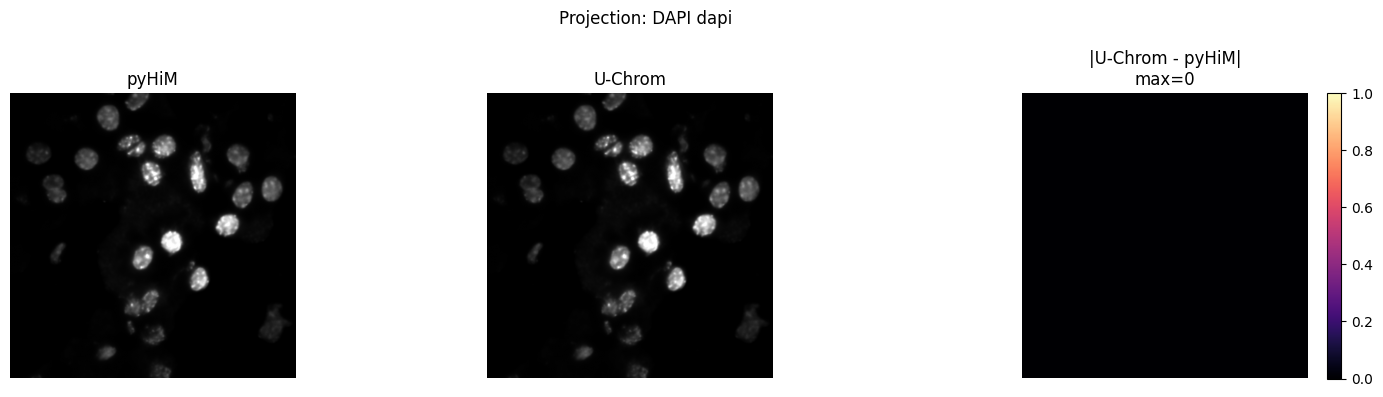

In [7]:
projection_rows = []
projection_examples = []
for round_name, spec in workspace.projections.items():
    for role, image in [("fiducial", spec["fiducial"])] + list(spec.get("images", {}).items()):
        pyhim_path = PYHIM_PROJECT_DATA / f"{image.name}.npy"
        if not pyhim_path.exists():
            projection_rows.append({"round": round_name, "role": role, "status": "missing", "path": str(pyhim_path)})
            continue
        pyhim_array = np.load(pyhim_path)
        row = finite_array_metrics(pyhim_array, image.data)
        row.update({"round": round_name, "role": role, "status": "ok", "path": str(pyhim_path)})
        projection_rows.append(row)
        projection_examples.append((round_name, role, pyhim_array, image.data))

display(pd.DataFrame(projection_rows))
if projection_examples:
    preferred = next(
        (example for example in projection_examples if example[0] == "DAPI" and example[1] == "dapi"),
        projection_examples[0],
    )
    round_name, role, pyhim_array, uchrom_array = preferred
    show_array_comparison(pyhim_array, uchrom_array, title=f"Projection: {round_name} {role}")


,shape_reference,shape_candidate,dtype_reference,dtype_candidate,shape_match,finite_fraction,exact_equal,max_abs_diff,mean_abs_diff,rmse,nrmse_by_ref_range,pearson,round,role,status,path
0,"(1024, 1024)","(1024, 1024)",uint16,float64,True,1.0,True,0.0,0.0,0.0,0.0,1.0,RT26,fiducial,ok,F:\project\Caolab\U-C-p\pyHiM\test\test_datase...
1,"(1024, 1024)","(1024, 1024)",uint16,float64,True,1.0,True,0.0,0.0,0.0,0.0,1.0,RT26,barcode,ok,F:\project\Caolab\U-C-p\pyHiM\test\test_datase...
2,"(1024, 1024)","(1024, 1024)",uint16,float64,True,1.0,True,0.0,0.0,0.0,0.0,1.0,RT27,fiducial,ok,F:\project\Caolab\U-C-p\pyHiM\test\test_datase...
3,"(1024, 1024)","(1024, 1024)",uint16,float64,True,1.0,True,0.0,0.0,0.0,0.0,1.0,RT27,barcode,ok,F:\project\Caolab\U-C-p\pyHiM\test\test_datase...
4,"(1024, 1024)","(1024, 1024)",uint16,float64,True,1.0,True,0.0,0.0,0.0,0.0,1.0,DAPI,fiducial,ok,F:\project\Caolab\U-C-p\pyHiM\test\test_datase...
5,"(1024, 1024)","(1024, 1024)",float64,float64,True,1.0,True,0.0,0.0,0.0,0.0,1.0,DAPI,dapi,ok,F:\project\Caolab\U-C-p\pyHiM\test\test_datase...


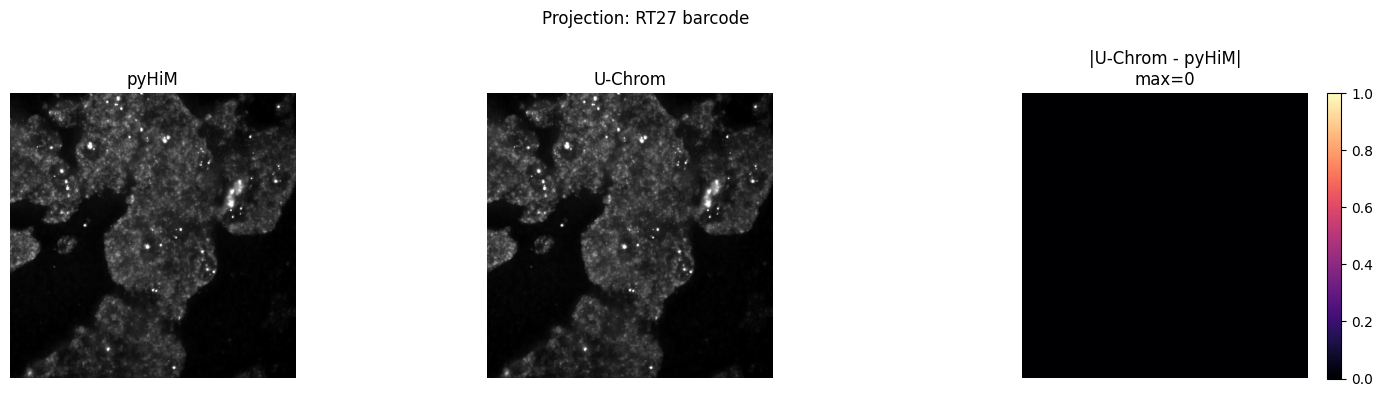

In [8]:
display(pd.DataFrame(projection_rows))
if projection_examples:
    preferred = next(
        (example for example in projection_examples if example[0] == "RT27" and example[1] == "barcode"),
        projection_examples[0],
    )
    round_name, role, pyhim_array, uchrom_array = preferred
    show_array_comparison(pyhim_array, uchrom_array, title=f"Projection: {round_name} {role}")

## Section 3: 2D Global Registration

In [9]:
workspace.register_global(
    reference=REFERENCE_ROUND,
    sample_id=SAMPLE_ID,
    roi=ROI,
    upsample_factor=100,
    align_by_block=True,
    block_size=128,
    tolerance=0.1,
    background_sigma=3.0,
)

if SAVE_MODE:
    workspace.save("register_global", OUT_DIR / "register_global", mode=SAVE_MODE)

{name: result.shift.tolist() for name, result in workspace.global_registration.rounds.items()}


{'RT26': [0.0, 0.0],
 'RT27': [5.114090897820213, -6.615454543720592],
 'DAPI': [-32.63235327776741, 19.282352784100702]}

### pyHiM 2D Global Registration Comparison

Registered images are compared pixel-wise. Shifts are compared from `shifts.json` because matching image artifacts alone can hide a wrong transform.


,shape_reference,shape_candidate,dtype_reference,dtype_candidate,shape_match,finite_fraction,exact_equal,max_abs_diff,mean_abs_diff,rmse,nrmse_by_ref_range,pearson,round,role,status,path
0,"(1024, 1024)","(1024, 1024)",uint16,float64,True,1.0,True,0.0,0.0,0.0,0.0,1.0,RT26,fiducial,ok,F:\project\Caolab\U-C-p\pyHiM\test\test_datase...
1,"(1024, 1024)","(1024, 1024)",uint16,float64,True,1.0,True,0.0,0.0,0.0,0.0,1.0,RT26,barcode,ok,F:\project\Caolab\U-C-p\pyHiM\test\test_datase...
2,"(1024, 1024)","(1024, 1024)",float32,float64,True,1.0,True,0.0,0.0,0.0,0.0,1.0,RT27,fiducial,ok,F:\project\Caolab\U-C-p\pyHiM\test\test_datase...
3,"(1024, 1024)","(1024, 1024)",uint16,float64,True,1.0,True,0.0,0.0,0.0,0.0,1.0,RT27,barcode,ok,F:\project\Caolab\U-C-p\pyHiM\test\test_datase...
4,"(1024, 1024)","(1024, 1024)",float32,float64,True,1.0,True,0.0,0.0,0.0,0.0,1.0,DAPI,fiducial,ok,F:\project\Caolab\U-C-p\pyHiM\test\test_datase...
5,"(1024, 1024)","(1024, 1024)",float64,float64,True,1.0,True,0.0,0.0,0.0,0.0,1.0,DAPI,dapi,ok,F:\project\Caolab\U-C-p\pyHiM\test\test_datase...


,round,pyhim_0,pyhim_1,uchrom_0,uchrom_1,delta_norm
0,RT27,5.114091,-6.615455,5.114091,-6.615455,0.0
1,DAPI,-32.632353,19.282353,-32.632353,19.282353,0.0


(<Figure size 1500x800 with 6 Axes>,
 array([[<Axes: title={'center': 'Uncorrected'}, ylabel='U-Chrom'>,
         <Axes: title={'center': 'Corrected'}>,
         <Axes: title={'center': 'Overlay'}>],
        [<Axes: ylabel='pyHiM'>, <Axes: >, <Axes: >]], dtype=object))

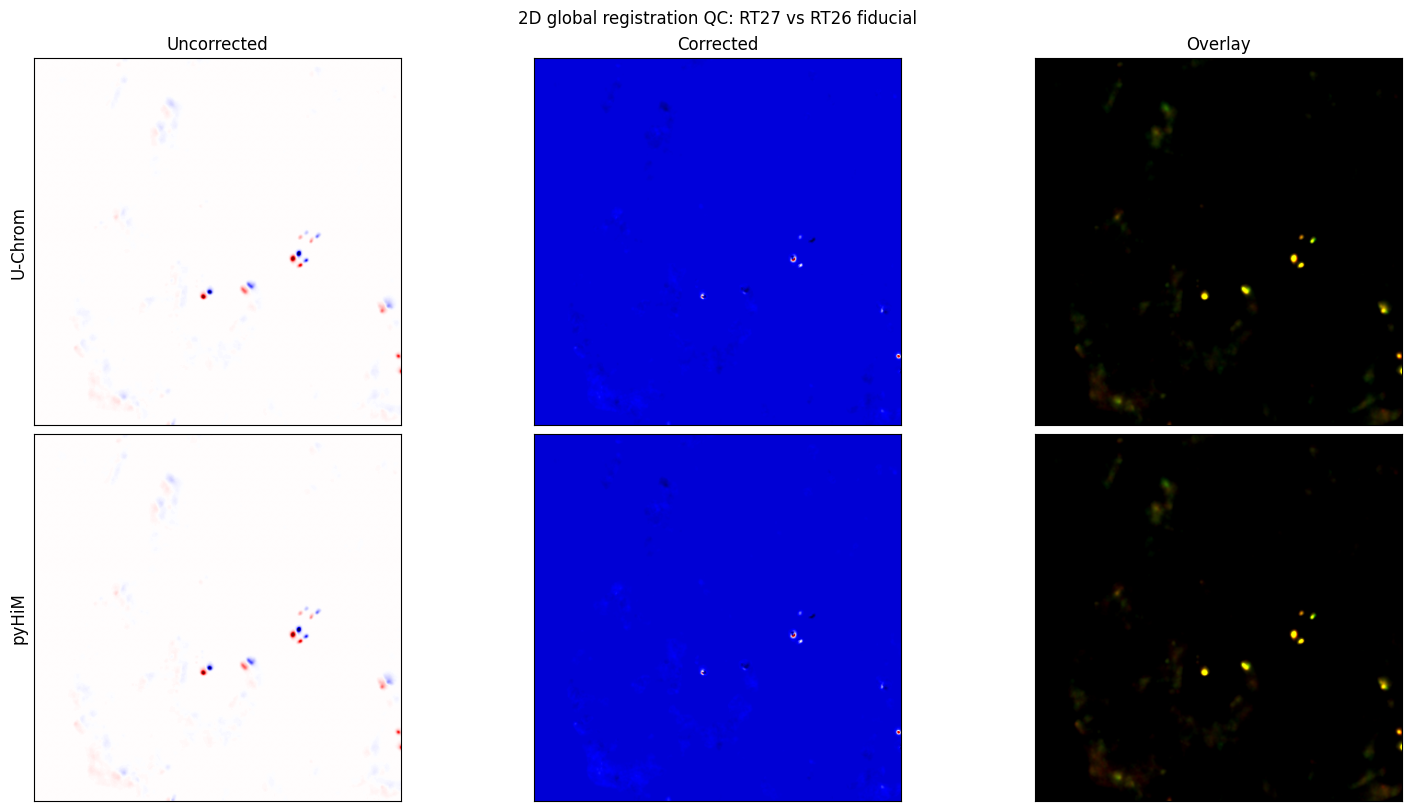

In [10]:
registration_rows = []
registration_examples = []
for round_name, rr in workspace.global_registration.rounds.items():
    candidates = [("fiducial", rr.fiducial.name, rr.registered_fiducial)]
    candidates += [(name, ir.input_image.name, ir.registered) for name, ir in rr.images.items()]
    for role, stem, array in candidates:
        pyhim_path = PYHIM_REGISTER_GLOBAL_DATA / f"{stem}_registered.npy"
        if not pyhim_path.exists():
            registration_rows.append({"round": round_name, "role": role, "status": "missing", "path": str(pyhim_path)})
            continue
        pyhim_array = np.load(pyhim_path)
        row = finite_array_metrics(pyhim_array, array)
        row.update({"round": round_name, "role": role, "status": "ok", "path": str(pyhim_path)})
        registration_rows.append(row)
        registration_examples.append((round_name, role, pyhim_array, array))

display(pd.DataFrame(registration_rows))

shift_path = PYHIM_REGISTER_GLOBAL_DATA / "shifts.json"
if shift_path.exists():
    pyhim_payload = json.loads(shift_path.read_text(encoding="utf-8"))
    pyhim_shifts = pyhim_payload.get(f"ROI:{ROI}", pyhim_payload)
    shift_rows = []
    for round_name, rr in workspace.global_registration.rounds.items():
        if round_name == workspace.global_registration.reference or round_name not in pyhim_shifts:
            continue
        py = np.asarray(pyhim_shifts[round_name], dtype=float)
        uc = np.asarray(rr.shift, dtype=float)
        shift_rows.append({"round": round_name, "pyhim_0": py[0], "pyhim_1": py[1], "uchrom_0": uc[0], "uchrom_1": uc[1], "delta_norm": float(np.linalg.norm(uc - py))})
    display(pd.DataFrame(shift_rows))

show_registration_qc_comparison(
    workspace.global_registration,
    moving_round="RT27",
    pyhim_project_data=PYHIM_PROJECT_DATA,
    pyhim_register_global_data=PYHIM_REGISTER_GLOBAL_DATA,
    reference_round=REFERENCE_ROUND,
    zoom=REGISTRATION_QC_ZOOM,
    overlay_gain=5.0,
    background_sigma=3.0,
)


## Section 4: 3D Local Registration

In [11]:
workspace.register_local(
    reference=REFERENCE_ROUND,
    method="block3d",
    block_size_xy=128,
    upsample_factor=100,
    lower_threshold=0.9,
    higher_threshold=0.9999,
    pixel_size_xy=0.1,
    pixel_size_z=0.25,
    z_binning=2,
)

if SAVE_MODE:
    workspace.save("register_local", OUT_DIR / "register_local", mode=SAVE_MODE)

workspace.local_registration.table.head()


d:\Miniconda3\envs\uchrom\lib\site-packages\skimage\registration\_phase_cross_correlation.py:112: RuntimeWarning: invalid value encountered in scalar divide
  error = 1.0 - cross_correlation_max * cross_correlation_max.conj() /\
d:\Miniconda3\envs\uchrom\lib\site-packages\skimage\registration\_phase_cross_correlation.py:112: RuntimeWarning: invalid value encountered in scalar divide
  error = 1.0 - cross_correlation_max * cross_correlation_max.conj() /\


,reference file,aligned file,blockXY,ROI #,label,block_i,block_j,shift_z,shift_x,shift_y,quality_xy,quality_zy,quality_zx
0,scan_001_RT26_005_ROI_converted_decon_ch00.tif,scan_001_RT27_005_ROI_converted_decon_ch00.tif,128,5,RT27,0,0,7.97,43.19,-47.97,1.069538,1.091496,1.071823
1,scan_001_RT26_005_ROI_converted_decon_ch00.tif,scan_001_RT27_005_ROI_converted_decon_ch00.tif,128,5,RT27,0,1,-0.22,-0.05,-1.42,0.679322,0.749728,0.677248
2,scan_001_RT26_005_ROI_converted_decon_ch00.tif,scan_001_RT27_005_ROI_converted_decon_ch00.tif,128,5,RT27,0,2,0.04,-0.08,0.00,0.384005,0.507052,0.440670
3,scan_001_RT26_005_ROI_converted_decon_ch00.tif,scan_001_RT27_005_ROI_converted_decon_ch00.tif,128,5,RT27,0,3,0.04,-0.16,-0.02,0.663053,0.693157,0.742731
4,scan_001_RT26_005_ROI_converted_decon_ch00.tif,scan_001_RT27_005_ROI_converted_decon_ch00.tif,128,5,RT27,0,4,1.02,0.92,-1.09,1.006137,0.937474,0.974174


### pyHiM 3D Local Registration Comparison

The quantitative target for local registration is the block shift table. Blocks are matched by aligned file, ROI and block indices. The projection QC below follows pyHiM visual semantics: red is the reference fiducial, green is the moving fiducial after block-wise 3D correction, blue is the block grid, and yellow means red/green overlap.


In [12]:
pyhim_local_path = PYHIM_REGISTER_LOCAL_DATA / "shifts_block3D.dat"
if pyhim_local_path.exists() and workspace.local_registration is not None:
    pyhim_local = read_ecsv(pyhim_local_path)
    uchrom_local = workspace.local_registration.table.copy()
    for table in (pyhim_local, uchrom_local):
        for col in ["aligned file", "reference file", "label"]:
            if col in table: table[col] = table[col].astype(str)
        for col in ["ROI #", "block_i", "block_j", "shift_z", "shift_x", "shift_y", "quality_xy", "quality_zy", "quality_zx"]:
            if col in table: table[col] = pd.to_numeric(table[col], errors="coerce")
    keys = [c for c in ["aligned file", "ROI #", "block_i", "block_j"] if c in pyhim_local and c in uchrom_local]
    merged = pyhim_local.merge(uchrom_local, on=keys, suffixes=("_pyhim", "_uchrom"))
    display(pd.DataFrame([{"source":"pyHiM", "rows":len(pyhim_local)}, {"source":"U-Chrom", "rows":len(uchrom_local)}, {"source":"matched blocks", "rows":len(merged)}]))
    rows = []
    for axis in ["shift_z", "shift_x", "shift_y"]:
        a, b = f"{axis}_pyhim", f"{axis}_uchrom"
        if a in merged and b in merged:
            delta = merged[b] - merged[a]
            rows.append({"axis": axis, "mean_abs_delta_px": float(delta.abs().mean()), "median_abs_delta_px": float(delta.abs().median()), "max_abs_delta_px": float(delta.abs().max())})
    display(pd.DataFrame(rows))
    display(merged.head())
else:
    print("Missing pyHiM local-registration table or U-Chrom local-registration result", pyhim_local_path)


,source,rows
0,pyHiM,128
1,U-Chrom,128
2,matched blocks,128


,axis,mean_abs_delta_px,median_abs_delta_px,max_abs_delta_px
0,shift_z,2.980349e-08,6.258488e-09,3.051758e-07
1,shift_x,1.062226e-07,2.086163e-09,1.831055e-06
2,shift_y,1.367339e-07,3.576279e-09,1.678467e-06


,reference file_pyhim,aligned file,blockXY_pyhim,ROI #,label_pyhim,block_i,block_j,shift_z_pyhim,shift_x_pyhim,shift_y_pyhim,...,quality_zx_pyhim,reference file_uchrom,blockXY_uchrom,label_uchrom,shift_z_uchrom,shift_x_uchrom,shift_y_uchrom,quality_xy_uchrom,quality_zy_uchrom,quality_zx_uchrom
0,scan_001_RT26_005_ROI_converted_decon_ch00.tif,scan_001_DAPI_005_ROI_converted_decon_ch01.tif,128,5,DAPI,0,0,-4.89,-60.610001,21.110001,...,0.660458,scan_001_RT26_005_ROI_converted_decon_ch00.tif,128,DAPI,-4.89,-60.61,21.11,0.848683,0.829148,0.660458
1,scan_001_RT26_005_ROI_converted_decon_ch00.tif,scan_001_DAPI_005_ROI_converted_decon_ch01.tif,128,5,DAPI,0,1,0.22,0.100000,-1.110000,...,0.663635,scan_001_RT26_005_ROI_converted_decon_ch00.tif,128,DAPI,0.22,0.10,-1.11,0.671850,0.650871,0.663635
2,scan_001_RT26_005_ROI_converted_decon_ch00.tif,scan_001_DAPI_005_ROI_converted_decon_ch01.tif,128,5,DAPI,0,2,-0.03,-0.790000,0.310000,...,0.709830,scan_001_RT26_005_ROI_converted_decon_ch00.tif,128,DAPI,-0.03,-0.79,0.31,0.532942,0.695031,0.709830
3,scan_001_RT26_005_ROI_converted_decon_ch00.tif,scan_001_DAPI_005_ROI_converted_decon_ch01.tif,128,5,DAPI,0,3,0.01,-1.990000,-0.300000,...,0.737469,scan_001_RT26_005_ROI_converted_decon_ch00.tif,128,DAPI,0.01,-1.99,-0.30,0.747963,0.848875,0.737469
4,scan_001_RT26_005_ROI_converted_decon_ch00.tif,scan_001_DAPI_005_ROI_converted_decon_ch01.tif,128,5,DAPI,0,4,-1.18,-0.040000,33.990002,...,1.044119,scan_001_RT26_005_ROI_converted_decon_ch00.tif,128,DAPI,-1.18,-0.04,33.99,1.173445,1.078037,1.044119


In [13]:
key_cols = ["aligned file", "block_i", "block_j"]

u_local = workspace.local_registration.table.sort_values(key_cols).reset_index(drop=True)
p_local = pyhim_local.sort_values(key_cols).reset_index(drop=True)

display(u_local.head(2))
display(p_local.head(2))

,reference file,aligned file,blockXY,ROI #,label,block_i,block_j,shift_z,shift_x,shift_y,quality_xy,quality_zy,quality_zx
0,scan_001_RT26_005_ROI_converted_decon_ch00.tif,scan_001_DAPI_005_ROI_converted_decon_ch01.tif,128,5,DAPI,0,0,-4.89,-60.61,21.11,0.848683,0.829148,0.660458
1,scan_001_RT26_005_ROI_converted_decon_ch00.tif,scan_001_DAPI_005_ROI_converted_decon_ch01.tif,128,5,DAPI,0,1,0.22,0.10,-1.11,0.671850,0.650871,0.663635


,reference file,aligned file,blockXY,ROI #,label,block_i,block_j,shift_z,shift_x,shift_y,quality_xy,quality_zy,quality_zx
0,scan_001_RT26_005_ROI_converted_decon_ch00.tif,scan_001_DAPI_005_ROI_converted_decon_ch01.tif,128,5,DAPI,0,0,-4.89,-60.610001,21.110001,0.848683,0.829148,0.660458
1,scan_001_RT26_005_ROI_converted_decon_ch00.tif,scan_001_DAPI_005_ROI_converted_decon_ch01.tif,128,5,DAPI,0,1,0.22,0.100000,-1.110000,0.671850,0.650871,0.663635


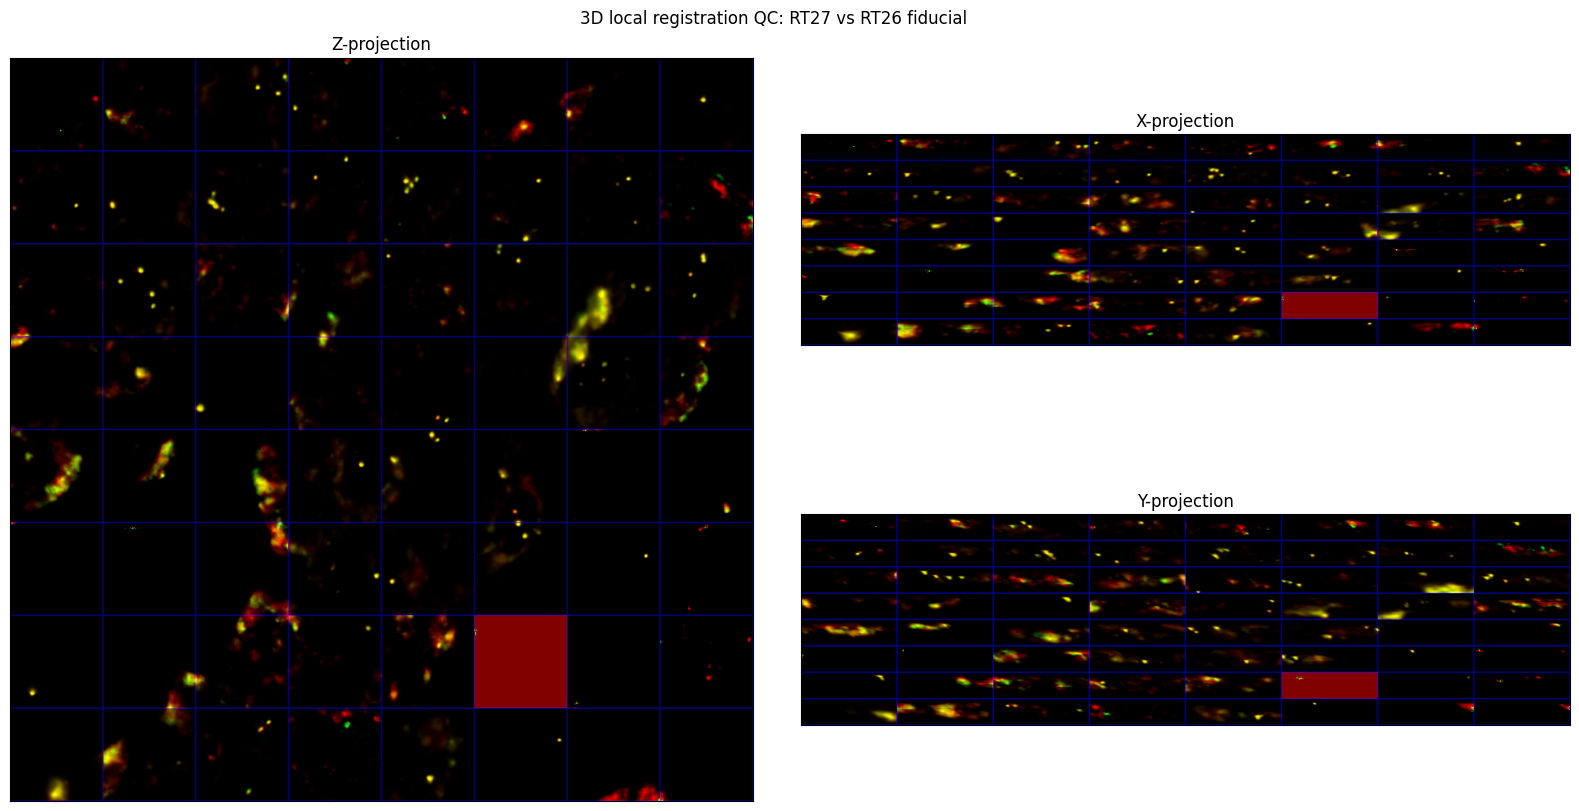

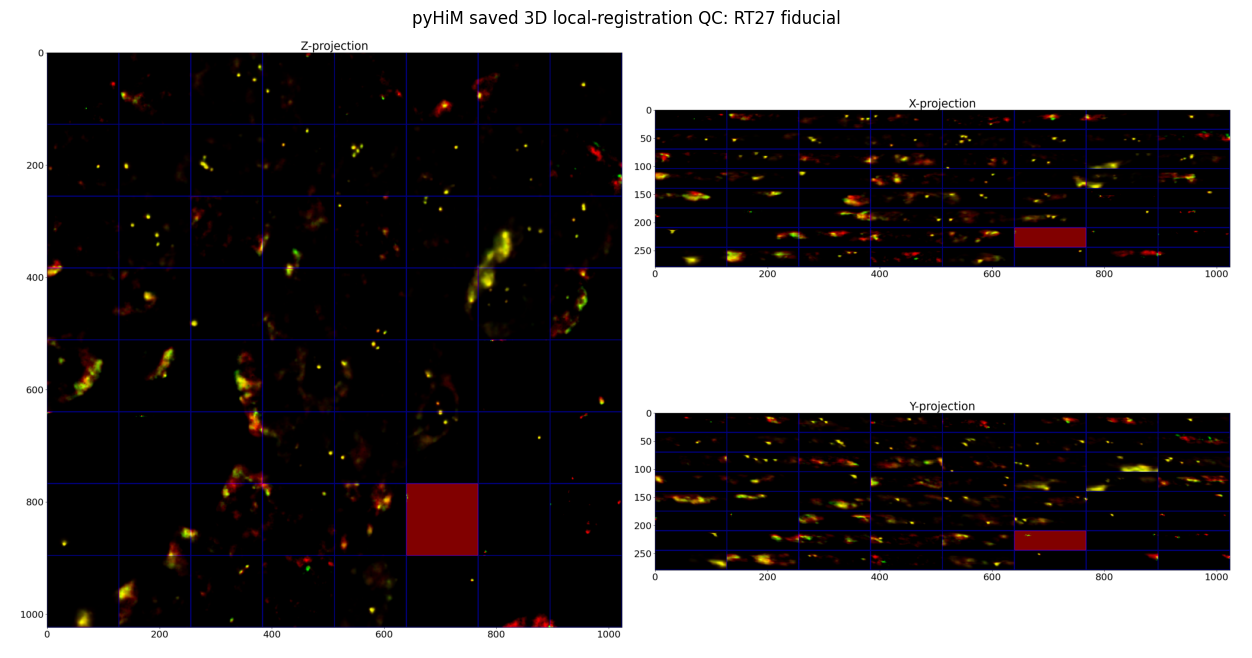

In [14]:
show_local_registration_3d_qc(
    workspace.raw_rounds,
    workspace.local_registration,
    global_registration=workspace.global_registration,
    moving_round=LOCAL_REGISTRATION_3D_QC_ROUND,
    reference_round=REFERENCE_ROUND,
    z_binning=Z_BINNING,
    lower_threshold=0.9,
    higher_threshold=0.9999,
    block_window=LOCAL_REGISTRATION_3D_QC_BLOCK_WINDOW,
    z_projection_crop=LOCAL_REGISTRATION_3D_QC_Z_CROP,
)

qc_image = workspace.raw_rounds[LOCAL_REGISTRATION_3D_QC_ROUND]["fiducial"]
qc_file = Path(qc_image.path).name if qc_image.path else f"{qc_image.name}.tif"
pyhim_3d_qc_png = PYHIM_DIR / "register_local" / f"{qc_file}_3Dalignments.png"
if pyhim_3d_qc_png.exists():
    pyhim_qc = plt.imread(pyhim_3d_qc_png)
    fig, ax = plt.subplots(figsize=(16, 8))
    ax.imshow(pyhim_qc)
    ax.axis("off")
    ax.set_title(f"pyHiM saved 3D local-registration QC: {LOCAL_REGISTRATION_3D_QC_ROUND} fiducial")
else:
    print("Missing pyHiM 3D QC image", pyhim_3d_qc_png)


## Section 5: Segmentation

In [ ]:
# For pyHiM-comparable 3D masks, let segment() apply pyHiM's global XY shift and z-binning.
dapi_3d_for_mask = workspace.raw_rounds["DAPI"]["images"]["dapi"]

workspace.masks["mask_3d"] = segment(
    dapi_3d_for_mask,
    method="pyhim_mask_3d",
    global_registration=workspace.global_registration,
    z_binning=Z_BINNING,
)

if SAVE_MODE:
    workspace.save("mask_3d", OUT_DIR / "mask_3d", mode=SAVE_MODE)

{"mask_3d": workspace.masks["mask_3d"].labels.shape}


### pyHiM Segmentation Comparison

The pyHiM saved mask figure uses a fixed `raw image` title for the grayscale input panel. The display cell below explicitly compares raw/z-binned and XY-corrected DAPI projections, then shows the input projection and label projection used for U-Chrom and pyHiM 3D masks. For equivalence, use quantitative checks as the acceptance criterion: foreground IoU/Dice tell whether the total mask area overlaps, and one-to-one label IoU tells whether individual nuclei match. Label IDs may be renumbered, so exact label values are not expected to match.


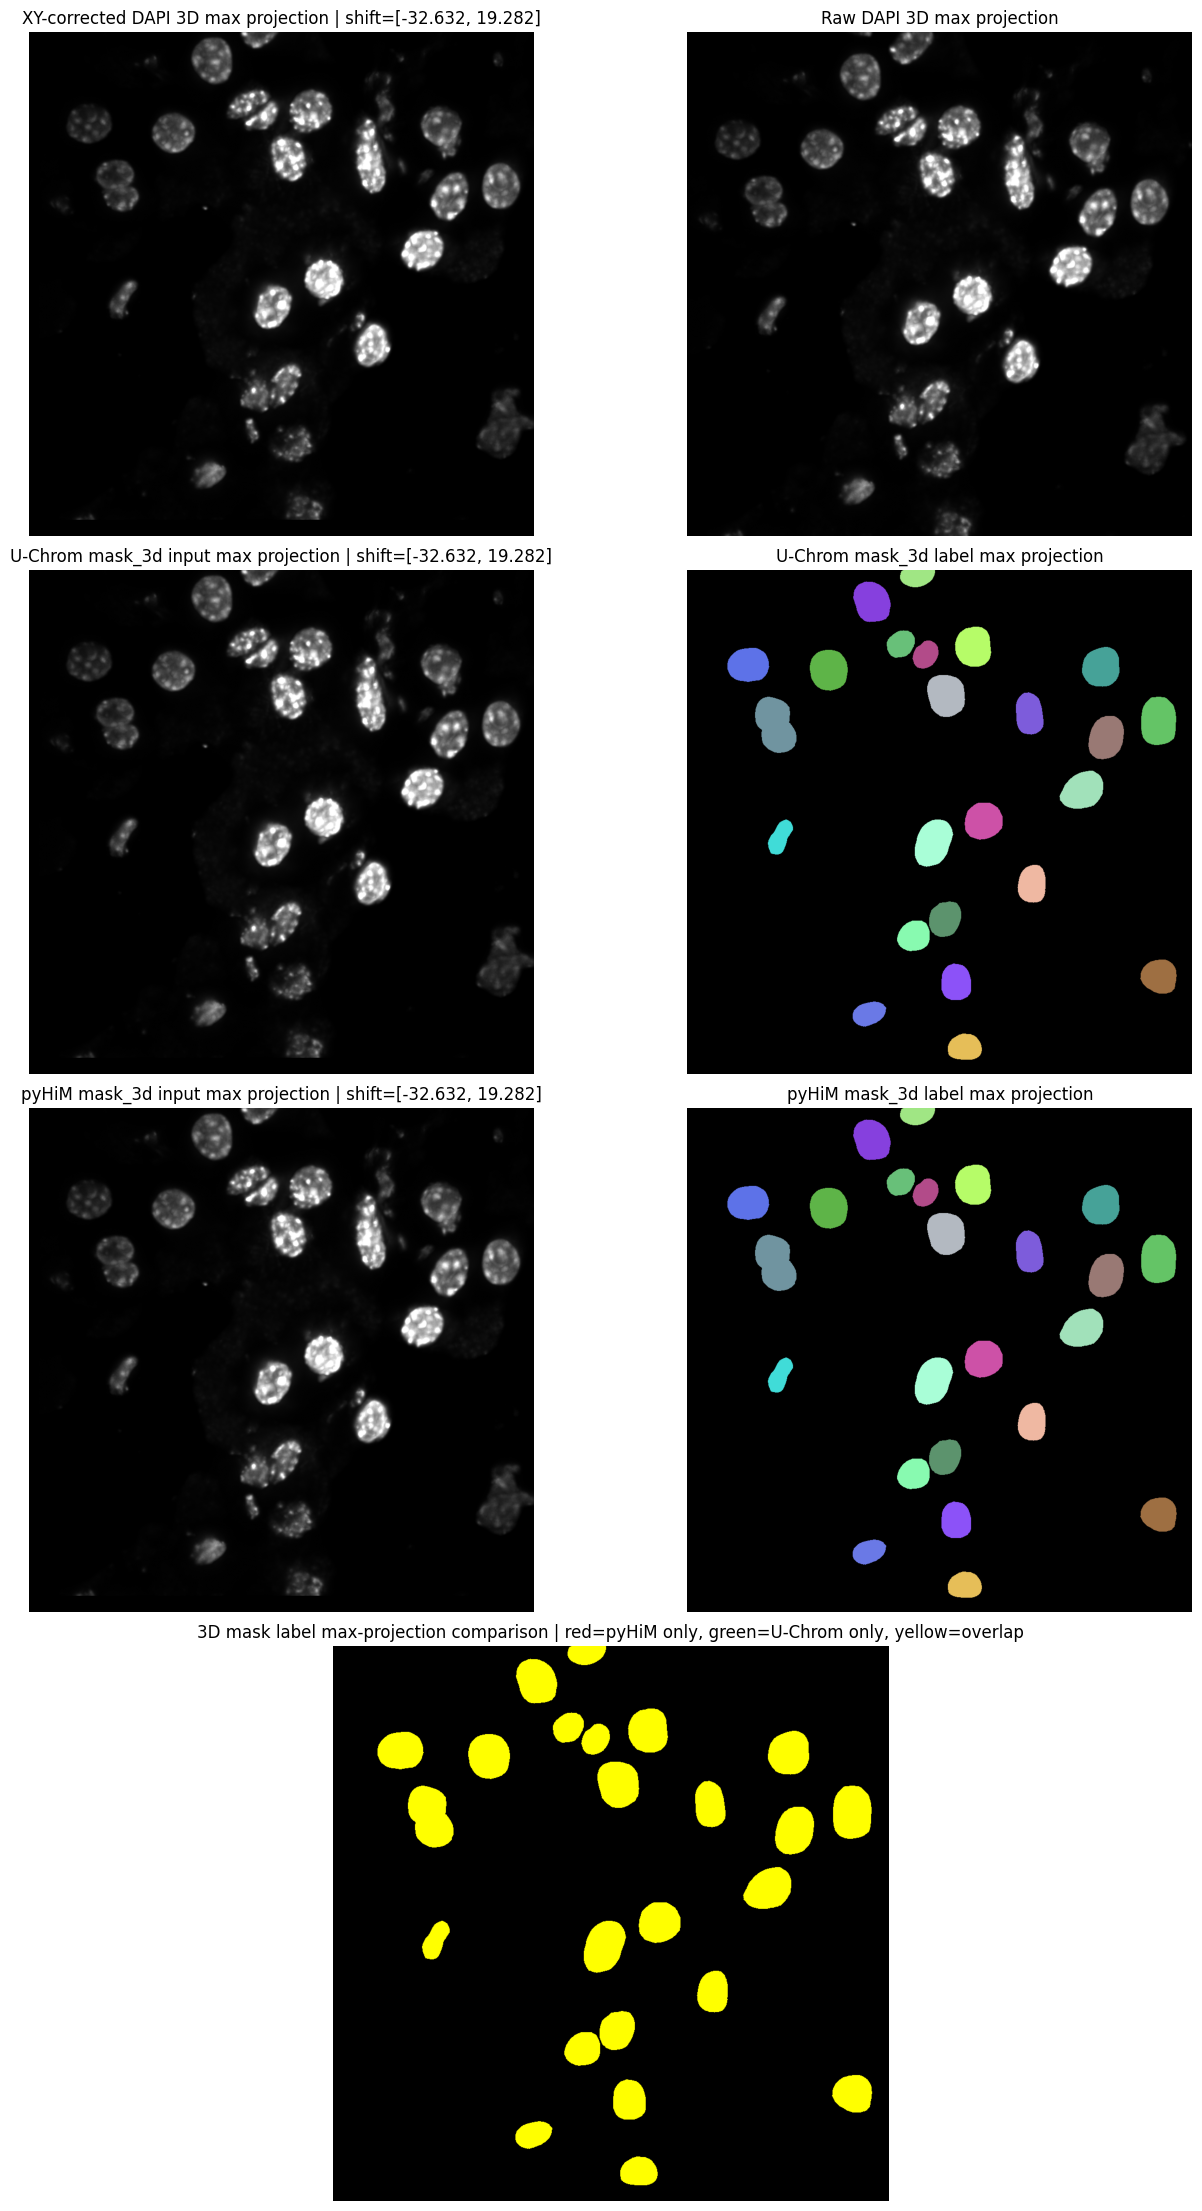

U-Chrom mask_3d meta: {'model_root': 'F:\\project\\Caolab\\U-C-p\\UC\\pyHiM_ref\\src\\stardist_models', 'model_name': 'DAPI_3D_stardist_17032021_deconvolved', 'model_dir': 'F:\\project\\Caolab\\U-C-p\\UC\\pyHiM_ref\\src\\stardist_models\\DAPI_3D_stardist_17032021_deconvolved', 'round': 'DAPI', 'role': 'dapi', 'coordinate_frame': 'global_registered', 'global_shift_yx': [-32.63235327776741, 19.282352784100702]}
pyHiM DAPI shift_yx: [-32.63235327776741, 19.282352784100702]


In [16]:
from uchrom.im._pyhim import apply_xy_shift_3d, global_shift_for_round, reinterpolate_z


def _array_data(value):
    return np.asarray(getattr(value, "data", value))


def _read_pyhim_shift(round_name):
    shift_path = PYHIM_REGISTER_GLOBAL_DATA / "shifts.json"
    if shift_path.exists():
        payload = json.loads(shift_path.read_text(encoding="utf-8"))
        shifts = payload.get(f"ROI:{ROI}", payload)
        if round_name in shifts:
            return np.asarray(shifts[round_name], dtype=float), shift_path
    if workspace.global_registration is not None:
        return (
            np.asarray(
                global_shift_for_round(workspace.global_registration, round_name, roi=ROI),
                dtype=float,
            ),
            shift_path,
        )
    return None, shift_path


def _norm2d(image):
    arr = np.asarray(image, dtype=float)
    finite = arr[np.isfinite(arr)]
    if finite.size == 0:
        return np.zeros_like(arr, dtype=float)
    lo, hi = np.nanpercentile(finite, [1, 99.5])
    if hi <= lo:
        lo, hi = float(np.nanmin(finite)), float(np.nanmax(finite))
    return np.clip((arr - lo) / (hi - lo + 1e-12), 0, 1)


def _crop2d(arr, crop=SEGMENTATION_QC_CROP):
    if crop is None:
        return arr
    y0, y1, x0, x1 = crop
    return arr[int(y0):int(y1), int(x0):int(x1)]


def _max2d(stack):
    arr = np.asarray(stack)
    return arr if arr.ndim == 2 else np.max(arr, axis=0)


def _label2d(labels):
    arr = np.asarray(labels)
    return arr if arr.ndim == 2 else np.max(arr, axis=0)


def _label_rgb(label_image):
    labels = np.asarray(label_image, dtype=np.int64)
    max_label = int(labels.max()) if labels.size else 0
    rng = np.random.default_rng(7)
    colors = rng.uniform(0.25, 1.0, size=(max_label + 1, 3))
    colors[0] = 0
    return colors[labels]


def _imshow_gray(ax, image, title):
    ax.imshow(_norm2d(_crop2d(image)), cmap="gray")
    ax.set_title(title)
    ax.axis("off")


def _imshow_label(ax, labels, title):
    ax.imshow(_crop2d(_label_rgb(labels)))
    ax.set_title(title)
    ax.axis("off")


dapi_round = "DAPI"
pyhim_shift_yx, pyhim_shift_path = _read_pyhim_shift(dapi_round)
apply_pyhim_dapi_shift = pyhim_shift_yx is not None and dapi_round != REFERENCE_ROUND

if "mask_3d" not in workspace.masks:
    raise RuntimeError("Run the U-Chrom mask_3d segmentation cell before this display cell.")

dapi_raw_3d = reinterpolate_z(
    _array_data(workspace.raw_rounds[dapi_round]["images"]["dapi"]),
    z_binning=Z_BINNING,
)
dapi_xy_3d = (
    apply_xy_shift_3d(dapi_raw_3d, pyhim_shift_yx)
    if apply_pyhim_dapi_shift
    else dapi_raw_3d
)

uc_mask_result = workspace.masks["mask_3d"]
uc_mask3d = np.asarray(uc_mask_result.labels)
uc_meta = getattr(uc_mask_result, "meta", {}) or {}
uc_shift_yx = uc_meta.get("global_shift_yx")
if uc_shift_yx is not None:
    uc_shift_yx = np.asarray(uc_shift_yx, dtype=float)
    uc_input_3d = apply_xy_shift_3d(dapi_raw_3d, uc_shift_yx)
    uc_input_title = f"U-Chrom mask_3d input max projection | shift={uc_shift_yx.round(3).tolist()}"
elif uc_meta.get("coordinate_frame") == "global_registered" and apply_pyhim_dapi_shift:
    uc_input_3d = dapi_xy_3d
    uc_input_title = f"U-Chrom mask_3d input max projection | shift={pyhim_shift_yx.round(3).tolist()}"
else:
    uc_input_3d = dapi_raw_3d
    uc_input_title = "U-Chrom mask_3d input max projection | raw/z-binned"

pyhim_mask3d_path = PYHIM_MASK_3D_DATA / "scan_001_DAPI_005_ROI_converted_decon_ch00_3Dmasks.npy"
if not pyhim_mask3d_path.exists():
    raise FileNotFoundError(pyhim_mask3d_path)
pyhim_mask3d = np.load(pyhim_mask3d_path)

pyhim_uses_shift = apply_pyhim_dapi_shift and "_unregistered" not in pyhim_mask3d_path.name
pyhim_input_3d = dapi_xy_3d if pyhim_uses_shift else dapi_raw_3d
pyhim_input_title = (
    f"pyHiM mask_3d input max projection | shift={pyhim_shift_yx.round(3).tolist()}"
    if pyhim_uses_shift
    else "pyHiM mask_3d input max projection | raw/z-binned"
)

uc_label2d = _label2d(uc_mask3d)
pyhim_label2d = _label2d(pyhim_mask3d)
shift_title = pyhim_shift_yx.round(3).tolist() if pyhim_shift_yx is not None else None

fig = plt.figure(figsize=(13, 22), constrained_layout=True)
gs = fig.add_gridspec(4, 2, height_ratios=[1, 1, 1, 1.1])

ax_xy = fig.add_subplot(gs[0, 0])
ax_raw = fig.add_subplot(gs[0, 1])
ax_uc_img = fig.add_subplot(gs[1, 0])
ax_uc_lbl = fig.add_subplot(gs[1, 1])
ax_py_img = fig.add_subplot(gs[2, 0])
ax_py_lbl = fig.add_subplot(gs[2, 1])
ax_overlay = fig.add_subplot(gs[3, :])

_imshow_gray(ax_xy, _max2d(dapi_xy_3d), f"XY-corrected DAPI 3D max projection | shift={shift_title}")
_imshow_gray(ax_raw, _max2d(dapi_raw_3d), "Raw DAPI 3D max projection")
_imshow_gray(ax_uc_img, _max2d(uc_input_3d), uc_input_title)
_imshow_label(ax_uc_lbl, uc_label2d, "U-Chrom mask_3d label max projection")
_imshow_gray(ax_py_img, _max2d(pyhim_input_3d), pyhim_input_title)
_imshow_label(ax_py_lbl, pyhim_label2d, "pyHiM mask_3d label max projection")

if pyhim_label2d.shape == uc_label2d.shape:
    py = _crop2d(pyhim_label2d > 0)
    uc = _crop2d(uc_label2d > 0)
    overlay = np.zeros(py.shape + (3,), dtype=float)
    overlay[py & ~uc] = [1, 0, 0]
    overlay[uc & ~py] = [0, 1, 0]
    overlay[py & uc] = [1, 1, 0]
    ax_overlay.imshow(overlay)
    ax_overlay.set_title(
        "3D mask label max-projection comparison | red=pyHiM only, green=U-Chrom only, yellow=overlap"
    )
else:
    ax_overlay.text(
        0.5,
        0.5,
        f"Shape mismatch: pyHiM {pyhim_label2d.shape} vs U-Chrom {uc_label2d.shape}",
        ha="center",
        va="center",
    )
    ax_overlay.set_title("3D mask label max-projection comparison")
ax_overlay.axis("off")
plt.show()

if pyhim_shift_path.exists() and pyhim_mask3d_path.stat().st_mtime < pyhim_shift_path.stat().st_mtime:
    print(
        "Warning: pyHiM mask_3d output is older than shifts.json; "
        "rerun pyhim -C mask_3d with the expected root folder before interpreting alignment."
    )
print("U-Chrom mask_3d meta:", uc_meta)
print("pyHiM DAPI shift_yx:", None if pyhim_shift_yx is None else pyhim_shift_yx.tolist())


## Section 6: Localization

In [24]:
# pyHiM localize_3d parameters from parameters_loaded.json.
PYHIM_LOCALIZE_3D_PARAMS = {
    "backend": "stardist",
    "reduce_planes": False,
    "threshold_over_std": 5.0,
    "area_min": 10,
    "area_max": 250,
    "brightest": 1100,
    "pixel_size_xy": 0.1,
    "pixel_size_z": 0.25,
    "z_binning": Z_BINNING,
    "psf_z": 500,
    "psf_yx": 200,
}
display(pd.DataFrame([PYHIM_LOCALIZE_3D_PARAMS]).T.rename(columns={0: "U-Chrom localize_3d value"}))

# For pyHiM-comparable localizations, let localize() apply pyHiM's global XY shift and z-binning.
# localize_3d does not assign CellID; trace-building attaches spots to mask_3d later.
barcode_stacks = {}
for round_name, round_data in workspace.raw_rounds.items():
    if "barcode" not in round_data["images"]:
        continue
    barcode_stacks[round_name] = round_data["images"]["barcode"]

workspace.localizations = localize(
    barcode_stacks,
    method="pyhim_3d",
    global_registration=workspace.global_registration,
    roi=ROI,
    **PYHIM_LOCALIZE_3D_PARAMS,
)

if SAVE_MODE:
    workspace.save("localize_3d", OUT_DIR / "localize_3d", mode=SAVE_MODE)

display(workspace.localizations.head())
display(workspace.localizations.table.groupby("Barcode #").size().rename("U-Chrom localize_3d spots"))


,U-Chrom localize_3d value
backend,stardist
reduce_planes,False
threshold_over_std,5.0
area_min,10
area_max,250
brightest,1100
pixel_size_xy,0.1
pixel_size_z,0.25
z_binning,2
psf_z,500


Loading network weights from 'weights_best.h5'.
Loading thresholds from 'thresholds.json'.
Using default values: prob_thresh=0.537191, nms_thresh=0.4.


functional.py (238): The structure of `inputs` doesn't match the expected structure.
Expected: ['input']
Received: inputs=Tensor(shape=(1, 64, 64, 64, 1))
  0%|          | 0/64 [00:00<?, ?it/s]functional.py (238): The structure of `inputs` doesn't match the expected structure.
Expected: ['input']
Received: inputs=Tensor(shape=(1, None, None, None, 1))
100%|██████████| 64/64 [00:55<00:00,  1.15it/s]


Loading network weights from 'weights_best.h5'.
Loading thresholds from 'thresholds.json'.
Using default values: prob_thresh=0.537191, nms_thresh=0.4.


100%|██████████| 64/64 [00:55<00:00,  1.16it/s]


,Buid,ROI #,CellID #,Barcode #,id,zcentroid,xcentroid,ycentroid,sharpness,roundness1,roundness2,npix,sky,peak,flux,mag,round,label
0,3c50a55e-acbb-443f-baa1-f0f910e95228,5,0,26,0,5.379947,271.094462,604.618573,0.464286,7.031116,0.464286,182,0.0,44.0,880.0,-7.361207,RT26,RT26
1,78f2b95e-6ca4-439b-921e-747c0952566b,5,0,26,1,5.992075,152.443413,630.606600,0.479911,7.432700,0.479911,215,0.0,630.0,12600.0,-10.250926,RT26,RT26
2,bd10b5cf-48a7-4b47-bb20-87cdbee08c4d,5,0,26,2,6.072535,223.307759,646.451507,0.485185,7.939032,0.485185,262,0.0,99.0,1980.0,-8.241663,RT26,RT26
3,af4bf095-b8b8-40f3-a667-f82aebb67416,5,0,26,3,6.247922,252.756223,697.624655,0.339394,8.116830,0.339394,280,0.0,61.0,1220.0,-7.715900,RT26,RT26
4,28b1cfb7-e661-4911-9690-20fb9e72fc0c,5,0,26,4,5.480060,131.052579,724.094058,0.430014,8.287163,0.430014,298,0.0,108.0,2160.0,-8.336134,RT26,RT26


Barcode #
26    188
27    263
Name: U-Chrom localize_3d spots, dtype: int64

### pyHiM Localization Comparison

The pyHiM localization QC image overlays detected barcode spots on a barcode image projection. It is useful for visual sanity checking: spots should sit on bright puncta, and missing/extra detections are often obvious. For quantitative comparison, do not use `Buid`: pyHiM generates UUIDs that are not stable across runs. Instead, compare three things: total spots, spots per barcode, and one-to-one nearest-neighbor distances within each `(ROI, Barcode #)` group. In the distance table, `distance_px` is the 3D distance between matched spots, and `dz/dx/dy` are `U-Chrom - pyHiM` coordinate differences.


Using pyHiM localize_3d: F:\project\Caolab\U-C-p\pyHiM\test\test_dataset\localize_3d\data\localizations_3D_barcode_version_0.dat


,source,n_localizations
0,pyHiM,461
1,U-Chrom,451


,pyHiM,U-Chrom
Barcode #,,
26,192,188
27,269,263


,pyhim_total,uchrom_total,matched,pyhim_match_rate,uchrom_match_rate,median_distance_px,p95_distance_px
0,461,451,443,0.960954,0.982262,0.00015,0.010595


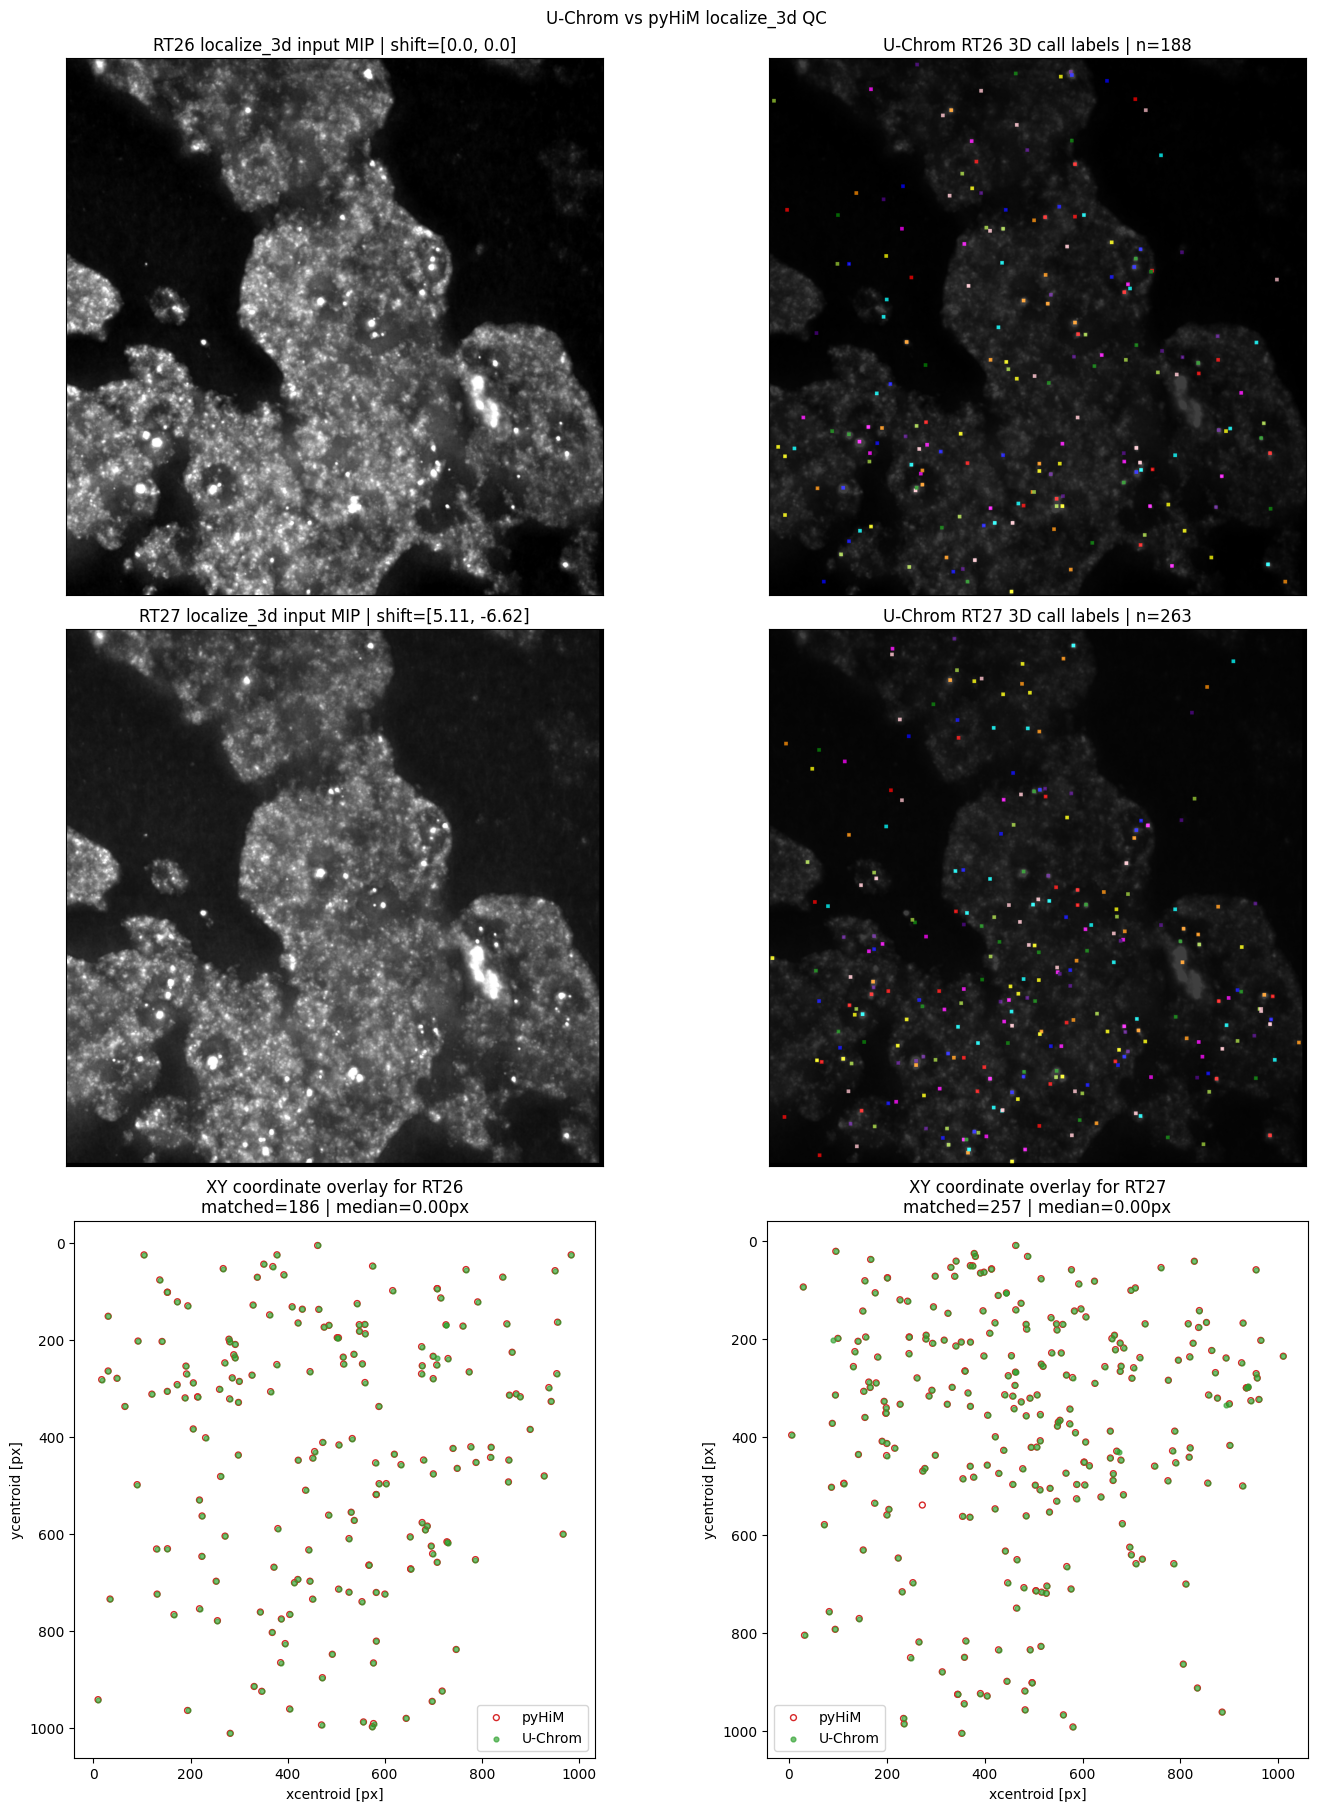

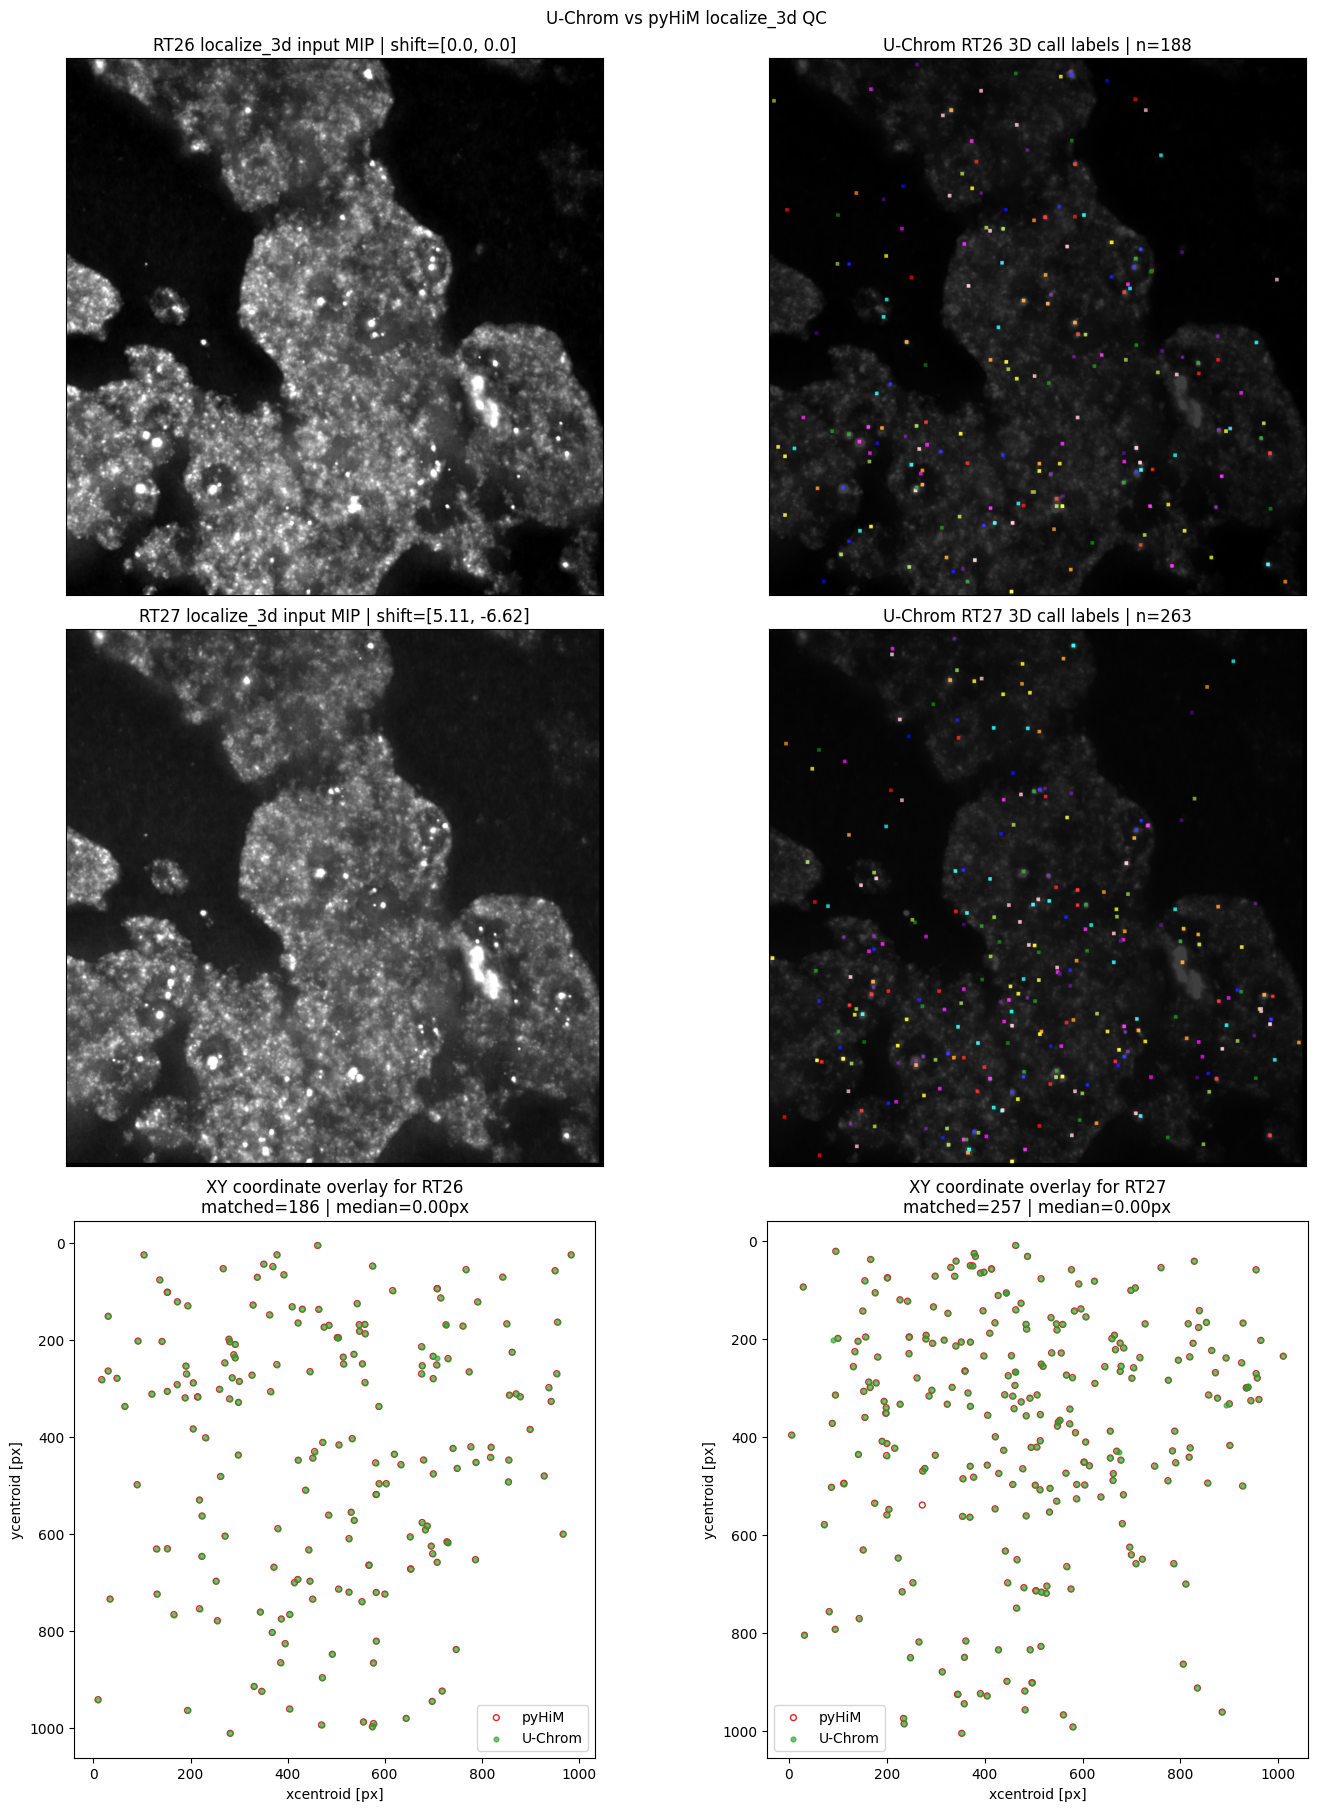

In [25]:
try:
    get_ipython().run_line_magic("matplotlib", "inline")
except Exception:
    pass

if "barcode_stacks" not in globals():
    barcode_stacks = {}
    for round_name, round_data in workspace.raw_rounds.items():
        if "barcode" in round_data["images"]:
            barcode_stacks[round_name] = round_data["images"]["barcode"]

if "PYHIM_LOCALIZE_3D_PARAMS" not in globals():
    PYHIM_LOCALIZE_3D_PARAMS = {
        "backend": "stardist",
        "reduce_planes": False,
        "threshold_over_std": 5.0,
        "area_min": 10,
        "area_max": 250,
        "brightest": 1100,
        "pixel_size_xy": 0.1,
        "pixel_size_z": 0.25,
        "z_binning": Z_BINNING,
        "psf_z": 500,
        "psf_yx": 200,
    }

if workspace.localizations is None:
    print("Running U-Chrom localize_3d with pyHiM-aligned parameters...")
    workspace.localizations = localize(
        barcode_stacks,
        method="pyhim_3d",
        global_registration=workspace.global_registration,
        roi=ROI,
        **PYHIM_LOCALIZE_3D_PARAMS,
    )

pyhim_locs_for_qc = None
if PYHIM_LOCALIZE_3D_PATH.exists():
    pyhim_locs_for_qc = read_ecsv(PYHIM_LOCALIZE_3D_PATH)
    print("Using pyHiM localize_3d:", PYHIM_LOCALIZE_3D_PATH)
else:
    print("Missing pyHiM localize_3d:", PYHIM_LOCALIZE_3D_PATH)

uc_locs_for_qc = workspace.localizations.table
count_summary, barcode_counts = localization_count_summary(pyhim_locs_for_qc, uc_locs_for_qc)
display(count_summary)
display(barcode_counts)
if pyhim_locs_for_qc is not None:
    loc_matches, loc_summary = match_localizations_by_position(
        pyhim_locs_for_qc,
        uc_locs_for_qc,
        max_distance_px=2.0,
    )
    display(pd.DataFrame([loc_summary]))

fig, axes = show_3d_call_alignment_qc(
    workspace.raw_rounds,
    uc_locs_for_qc,
    pyhim_localizations=pyhim_locs_for_qc,
    global_registration=workspace.global_registration,
    roi=ROI,
    rounds=("RT26", "RT27"),
    projection="max",
    z_binning=Z_BINNING,
    match_distance_px=2.0,
    title="U-Chrom vs pyHiM localize_3d QC",
)
display(fig)


In [26]:
row = workspace.localizations.table[
    (workspace.localizations.table["Barcode #"] == 26)
]

row

,Buid,ROI #,CellID #,Barcode #,id,zcentroid,xcentroid,ycentroid,sharpness,roundness1,roundness2,npix,sky,peak,flux,mag,round,label
0,3c50a55e-acbb-443f-baa1-f0f910e95228,5,0,26,0,5.379947,271.094462,604.618573,0.464286,7.031116,0.464286,182,0.0,44.0,880.0,-7.361207,RT26,RT26
1,78f2b95e-6ca4-439b-921e-747c0952566b,5,0,26,1,5.992075,152.443413,630.606600,0.479911,7.432700,0.479911,215,0.0,630.0,12600.0,-10.250926,RT26,RT26
2,bd10b5cf-48a7-4b47-bb20-87cdbee08c4d,5,0,26,2,6.072535,223.307759,646.451507,0.485185,7.939032,0.485185,262,0.0,99.0,1980.0,-8.241663,RT26,RT26
3,af4bf095-b8b8-40f3-a667-f82aebb67416,5,0,26,3,6.247922,252.756223,697.624655,0.339394,8.116830,0.339394,280,0.0,61.0,1220.0,-7.715900,RT26,RT26
4,28b1cfb7-e661-4911-9690-20fb9e72fc0c,5,0,26,4,5.480060,131.052579,724.094058,0.430014,8.287163,0.430014,298,0.0,108.0,2160.0,-8.336134,RT26,RT26
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
183,97d1ca28-fcff-4e09-8578-20fde88816ce,5,0,26,183,26.386034,556.329668,987.536593,0.505952,7.867689,0.505952,255,0.0,262.0,5240.0,-9.298328,RT26,RT26
184,83049a9e-28f0-47aa-b86d-e7aae9198a7b,5,0,26,184,27.696205,421.515879,165.400000,0.478175,7.720987,0.478175,241,0.0,1042.0,20840.0,-10.797244,RT26,RT26
185,4889f346-fd84-4989-9701-67e8c3995c60,5,0,26,185,29.713116,676.098360,214.261911,0.526042,7.279769,0.526042,202,0.0,2976.0,59520.0,-11.936657,RT26,RT26
186,f7889b71-b20d-4034-8e73-cc7616989cf5,5,0,26,186,30.106949,675.947477,270.199932,0.514403,7.815926,0.514403,250,0.0,294.0,5880.0,-9.423443,RT26,RT26


## Section 7: Trace / Matrix

In [ ]:
if "barcode_stacks" not in globals():
    barcode_stacks = {}
    for round_name, round_data in workspace.raw_rounds.items():
        if "barcode" in round_data["images"]:
            barcode_stacks[round_name] = round_data["images"]["barcode"]

if "PYHIM_LOCALIZE_3D_PARAMS" not in globals():
    PYHIM_LOCALIZE_3D_PARAMS = {
        "backend": "stardist",
        "reduce_planes": False,
        "threshold_over_std": 5.0,
        "area_min": 10,
        "area_max": 250,
        "brightest": 1100,
        "pixel_size_xy": 0.1,
        "pixel_size_z": 0.25,
        "z_binning": Z_BINNING,
        "psf_z": 500,
        "psf_yx": 200,
    }

if workspace.localizations is None:
    print("Running U-Chrom localize_3d with pyHiM-aligned parameters before filtering...")
    workspace.localizations = localize(
        barcode_stacks,
        method="pyhim_3d",
        global_registration=workspace.global_registration,
        roi=ROI,
        **PYHIM_LOCALIZE_3D_PARAMS,
    )

PYHIM_FILTER_LOCALIZATIONS_PARAMS = {"flux_min_3D": 10.0}
display(pd.DataFrame(
    [{"parameter": key, "value": value} for key, value in PYHIM_FILTER_LOCALIZATIONS_PARAMS.items()]
))

uc_filter_before = (
    workspace.localizations.table.copy()
    if hasattr(workspace.localizations, "table")
    else pd.DataFrame(workspace.localizations).copy()
)
filtered = filter_localizations(workspace.localizations, **PYHIM_FILTER_LOCALIZATIONS_PARAMS)
workspace.filtered_localizations = filtered

pyhim_filter_before = None
pyhim_filter_expected = None
if PYHIM_LOCALIZE_3D_PATH.exists():
    pyhim_filter_before = read_ecsv(PYHIM_LOCALIZE_3D_PATH)
    pyhim_filter_expected = filter_localizations(
        pyhim_filter_before,
        **PYHIM_FILTER_LOCALIZATIONS_PARAMS,
    )
else:
    print("Missing pyHiM localize_3d input for filter QC:", PYHIM_LOCALIZE_3D_PATH)

pyhim_filter_saved = None
pyhim_filter_saved_path = None
if PYHIM_FILTER_LOCALIZE_3D_PATH.exists():
    pyhim_filter_saved_path = PYHIM_FILTER_LOCALIZE_3D_PATH
    pyhim_filter_saved = read_ecsv(pyhim_filter_saved_path)
elif PYHIM_REGISTERED_LOCALIZE_3D_PATH.exists():
    candidate = read_ecsv(PYHIM_REGISTERED_LOCALIZE_3D_PATH)
    if pyhim_filter_expected is None or len(candidate) == len(pyhim_filter_expected):
        pyhim_filter_saved_path = PYHIM_REGISTERED_LOCALIZE_3D_PATH
        pyhim_filter_saved = candidate
    else:
        print(
            "Skipping current pyHiM localizations_3D_barcode.dat for filter QC; "
            f"it has {len(candidate)} rows, while flux filtering gives {len(pyhim_filter_expected)}. "
            "This table is likely post-register."
        )

if pyhim_filter_saved_path is not None:
    print("Using pyHiM filter_localizations table:", pyhim_filter_saved_path)


def _flux_min_for_display(table):
    if table is None or "flux" not in table or len(table) == 0:
        return None
    values = pd.to_numeric(table["flux"], errors="coerce")
    if not values.notna().any():
        return None
    return float(values.min())


def _filter_count_row(source, before, after, path=None):
    return {
        "source": source,
        "before": len(before) if before is not None else None,
        "after": len(after) if after is not None else None,
        "removed": (len(before) - len(after)) if before is not None and after is not None else None,
        "flux_min_after": _flux_min_for_display(after),
        "path": str(path) if path is not None else "",
    }


filter_rows = [_filter_count_row("U-Chrom", uc_filter_before, filtered)]
if pyhim_filter_before is not None and pyhim_filter_expected is not None:
    filter_rows.append(
        _filter_count_row(
            "pyHiM expected",
            pyhim_filter_before,
            pyhim_filter_expected,
            PYHIM_LOCALIZE_3D_PATH,
        )
    )
if pyhim_filter_saved is not None:
    filter_rows.append(
        _filter_count_row(
            "pyHiM saved filter table",
            pyhim_filter_before,
            pyhim_filter_saved,
            pyhim_filter_saved_path,
        )
    )

display(pd.DataFrame(filter_rows))


def _barcode_filter_counts(source, before, after):
    if before is None or after is None or "Barcode #" not in before or "Barcode #" not in after:
        return pd.DataFrame()
    before_counts = pd.to_numeric(before["Barcode #"], errors="coerce").value_counts().sort_index()
    after_counts = pd.to_numeric(after["Barcode #"], errors="coerce").value_counts().sort_index()
    counts = pd.concat(
        [before_counts.rename("before"), after_counts.rename("after")],
        axis=1,
    ).fillna(0).astype(int)
    counts["removed"] = counts["before"] - counts["after"]
    counts.insert(0, "source", source)
    return counts.reset_index().rename(columns={"index": "Barcode #"})


barcode_filter_counts = pd.concat(
    [
        _barcode_filter_counts("U-Chrom", uc_filter_before, filtered),
        _barcode_filter_counts("pyHiM expected", pyhim_filter_before, pyhim_filter_expected),
    ],
    ignore_index=True,
)
if not barcode_filter_counts.empty:
    display(barcode_filter_counts)

pyhim_filtered_for_qc = pyhim_filter_saved if pyhim_filter_saved is not None else pyhim_filter_expected
if pyhim_filtered_for_qc is not None:
    count_summary, barcode_counts = localization_count_summary(pyhim_filtered_for_qc, filtered)
    display(count_summary)
    display(barcode_counts)
    filter_matches, filter_match_summary = match_localizations_by_position(
        pyhim_filtered_for_qc,
        filtered,
        max_distance_px=2.0,
    )
    display(pd.DataFrame([filter_match_summary]))

    fig, axes = show_3d_call_alignment_qc(
        workspace.raw_rounds,
        filtered,
        pyhim_localizations=pyhim_filtered_for_qc,
        global_registration=workspace.global_registration,
        roi=ROI,
        rounds=("RT26", "RT27"),
        projection="max",
        z_binning=Z_BINNING,
        match_distance_px=2.0,
        title="Filtered 3D calls | flux_min_3D >= 10.0",
    )
    display(fig)
else:
    print("Missing pyHiM filter_localizations table for comparison.")

registered_locs = register_localizations(
    filtered,
    global_registration=workspace.global_registration,
    local_registration=workspace.local_registration,
    tolerance_drift=LOCALIZATION_TOLERANCE_DRIFT,
    remove_uncorrected_localizations=REMOVE_UNCORRECTED_LOCALIZATIONS,
)

workspace.traces = build_traces(
    registered_locs,
    masks=workspace.masks.get("mask_3d"),
    method="KDtree",
    distance_threshold_um=1.0,
    pixel_size_xy=0.1,
    pixel_size_z=0.25,
    roi=ROI,
)

workspace.matrices = build_matrix(workspace.traces)

if SAVE_MODE:
    workspace.save("tracing", OUT_DIR / "tracing", mode=SAVE_MODE)
    workspace.save("matrix", OUT_DIR / "matrix", mode=SAVE_MODE)

workspace.matrices.matrices.keys()


### pyHiM Trace And Matrix Comparison

This section checks whether localization differences propagate into chromatin traces and distance matrices. `Trace_ID` values are implementation-specific, so equality of IDs is not expected. First compare trace table scale: number of rows, number of traces, median spots per trace and rows per barcode. Then compare matrices on the same barcode set. pyHiM stores `PWDscMatrix` as `(barcode, barcode, trace/cell)`, so it is collapsed with `nanmedian(axis=2)` before comparing to U-Chrom?s current median matrix. `Nmatrix` is the number of observations per barcode pair.


,source,rows,unique_traces,median_spots_per_trace,unique_barcodes
0,pyHiM,6917,3519,1.0,25
1,U-Chrom,249,194,1.0,2


,pyHiM,U-Chrom
Barcode #,,
1,477,0
2,250,0
3,268,0
7,173,0
8,201,0
9,337,0
10,358,0
11,192,0
12,258,0


d:\Miniconda3\envs\uchrom\lib\site-packages\numpy\lib\nanfunctions.py:1217: RuntimeWarning: All-NaN slice encountered
  return function_base._ureduce(a, func=_nanmedian, keepdims=keepdims,


,pyhim_matrix_shape,uchrom_matrix_shape,pyhim_barcodes,uchrom_barcodes,common_barcodes
0,"(25, 25)","(2, 2)","[1, 2, 3, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16,...","[26, 27]","[26, 27]"


,matrix,shape_reference,shape_candidate,dtype_reference,dtype_candidate,shape_match,finite_fraction,exact_equal,max_abs_diff,mean_abs_diff,rmse,nrmse_by_ref_range,pearson,finite_overlap_fraction
0,PWDscMatrix median on common barcodes,"(2, 2)","(2, 2)",float64,float64,True,0.5,False,0.060474,0.060474,0.060474,NaN,NaN,0.5
1,Nmatrix on common barcodes,"(2, 2)","(2, 2)",int32,float64,True,1.0,False,127.000000,70.000000,87.272562,1.28342,-0.995212,1.0


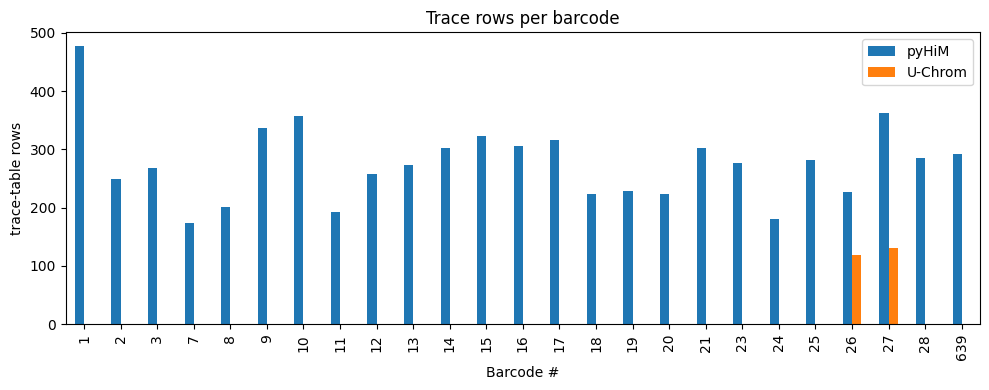

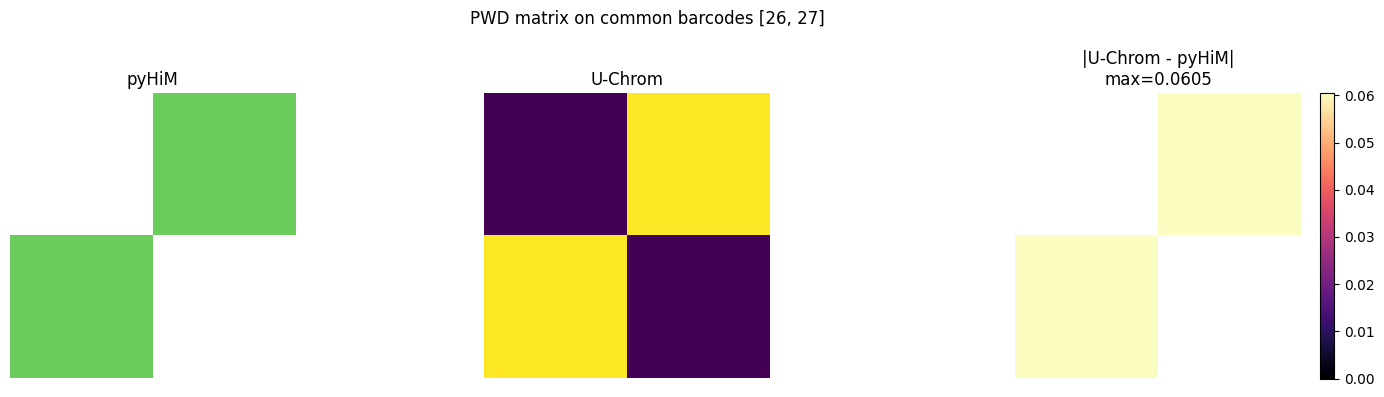

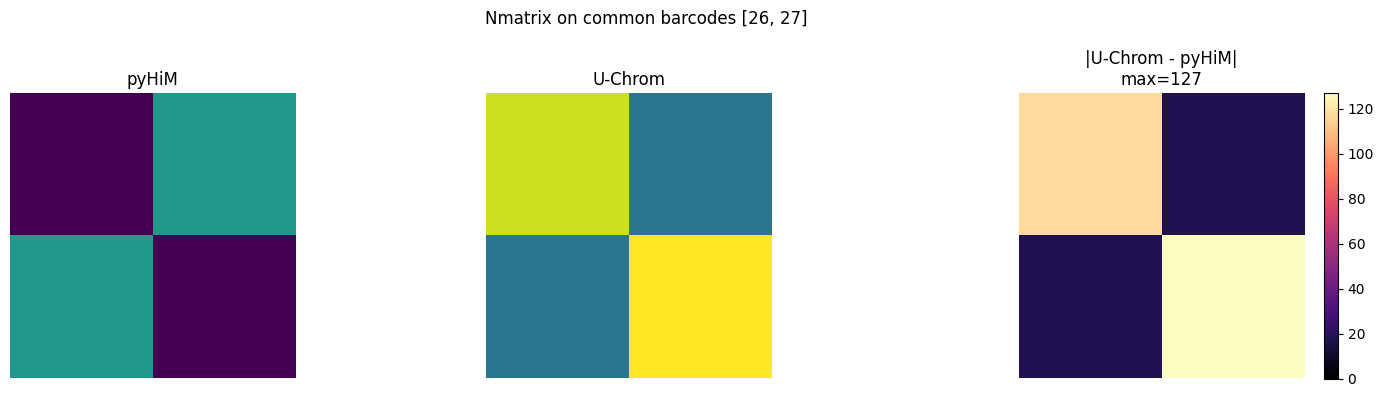

In [18]:
pyhim_trace_path = PYHIM_TRACE_DATA / "Trace_3D_barcode_KDtree_ROI-5.ecsv"
pyhim_pwd_path = PYHIM_TRACE_DATA / "Trace_3D_barcode_KDtree_ROI-5_Matrix_PWDscMatrix.npy"
pyhim_nmatrix_path = PYHIM_TRACE_DATA / "Trace_3D_barcode_KDtree_ROI-5_Matrix_Nmatrix.npy"
pyhim_unique_path = PYHIM_TRACE_DATA / "Trace_3D_barcode_KDtree_ROI-5_Matrix_uniqueBarcodes.ecsv"

if pyhim_trace_path.exists() and workspace.traces is not None:
    pyhim_traces = read_ecsv(pyhim_trace_path)
    uc_traces = workspace.traces.table
    display(pd.DataFrame([trace_summary(pyhim_traces, "pyHiM"), trace_summary(uc_traces, "U-Chrom")]))
    if "Barcode #" in pyhim_traces and "Barcode #" in uc_traces:
        trace_counts = pd.concat([
            pd.to_numeric(pyhim_traces["Barcode #"], errors="coerce").value_counts().sort_index().rename("pyHiM"),
            pd.to_numeric(uc_traces["Barcode #"], errors="coerce").value_counts().sort_index().rename("U-Chrom"),
        ], axis=1).fillna(0).astype(int)
        display(trace_counts)
        trace_counts.plot(kind="bar", figsize=(10, 4), title="Trace rows per barcode")
        plt.ylabel("trace-table rows")
        plt.tight_layout()
else:
    print("Missing pyHiM trace table or U-Chrom trace result", pyhim_trace_path)

if pyhim_pwd_path.exists() and pyhim_nmatrix_path.exists() and workspace.matrices is not None:
    pyhim_pwd_raw = np.load(pyhim_pwd_path)
    pyhim_pwd_median = np.nanmedian(pyhim_pwd_raw, axis=2) if pyhim_pwd_raw.ndim == 3 else pyhim_pwd_raw
    pyhim_nmatrix = np.load(pyhim_nmatrix_path)
    pyhim_barcodes = np.atleast_1d(np.loadtxt(pyhim_unique_path, dtype=int)) if pyhim_unique_path.exists() else np.arange(pyhim_pwd_median.shape[0])

    uc_pwd = workspace.matrices["PWDscMatrix"]
    uc_nmatrix = workspace.matrices["Nmatrix"]
    uc_barcodes = np.asarray(workspace.matrices["uniqueBarcodes"], dtype=int)
    common_barcodes = [int(b) for b in uc_barcodes if int(b) in set(pyhim_barcodes.astype(int))]
    display(pd.DataFrame([{
        "pyhim_matrix_shape": pyhim_pwd_median.shape,
        "uchrom_matrix_shape": uc_pwd.shape,
        "pyhim_barcodes": list(pyhim_barcodes.astype(int)),
        "uchrom_barcodes": list(uc_barcodes.astype(int)),
        "common_barcodes": common_barcodes,
    }]))

    if common_barcodes:
        py_idx = [int(np.where(pyhim_barcodes.astype(int) == b)[0][0]) for b in common_barcodes]
        uc_idx = [int(np.where(uc_barcodes.astype(int) == b)[0][0]) for b in common_barcodes]
        pyhim_pwd_common = pyhim_pwd_median[np.ix_(py_idx, py_idx)]
        uc_pwd_common = uc_pwd[np.ix_(uc_idx, uc_idx)]
        pyhim_nmatrix_common = pyhim_nmatrix[np.ix_(py_idx, py_idx)]
        uc_nmatrix_common = uc_nmatrix[np.ix_(uc_idx, uc_idx)]
        display(pd.DataFrame([
            {"matrix": "PWDscMatrix median on common barcodes", **matrix_metrics(pyhim_pwd_common, uc_pwd_common)},
            {"matrix": "Nmatrix on common barcodes", **matrix_metrics(pyhim_nmatrix_common, uc_nmatrix_common)},
        ]))
        show_matrix_comparison(pyhim_pwd_common, uc_pwd_common, title=f"PWD matrix on common barcodes {common_barcodes}")
        show_matrix_comparison(pyhim_nmatrix_common, uc_nmatrix_common, title=f"Nmatrix on common barcodes {common_barcodes}")
    else:
        print("No common barcodes between pyHiM and U-Chrom matrices; matrix values cannot be compared yet.")
else:
    print("Missing pyHiM matrix outputs or U-Chrom matrix result")


## Section 8: Current Alignment Status

Current implementation status relative to pyHiM:

- Projection and 2D global registration are the closest to pyHiM and can be judged with pixel-wise metrics.
- 3D local registration is now migrated through the pyHiM block3D path: U-Chrom estimates per-block `shift_z/shift_x/shift_y`, computes projection NRMSE quality matrices, and applies per-block shifts during localization registration with pyHiM-style `toleranceDrift` and `remove_uncorrected_localizations`.
- Segmentation now has a pyHiM-aligned backend under `method="pyhim"`. The acceptance check is still the same: use mask IoU and label matching against pyHiM outputs.
- Localization now has a pyHiM-aligned 3D backend under `method="pyhim_3d"`, with pyHiM StarDist/threshold segmentation and apifish sub-pixel fitting when the optional dependencies are installed. `Buid` should not be used for cross-tool matching.
- Trace/matrix is structurally compatible but not fully output-equivalent. U-Chrom currently returns a 2D median PWD matrix, while pyHiM stores a per-trace PWD stack plus derived matrices.

Use the comparison cells above as acceptance checks. When a step fails, first check input equivalence, then algorithm equivalence, then output-format equivalence.
